
TAYLOE BASEBAND MODEL
R_SOURCE_RF (RF input impedance):   8.0 ohm (by design)
R_on (74CBTLV3253):                 5.0 ohm

20m: C = 2.2 nF  ->  fc = 5.565 MHz
40m: C = 4.3 nF  ->  fc = 2.847 MHz
Default (20m): fc = 5.565 MHz

Response at key frequencies (20m Tayloe):
    freq (kHz)    |H_tayloe| (dB)
--------------------------------
           1.0            -0.0000
           4.0            -0.0000
           8.0            -0.0000
          16.0            -0.0000
          24.0            -0.0001
          48.0            -0.0003
          96.0            -0.0013
         188.0            -0.0050
         196.0            -0.0054

PASSIVE RC2 OPTIMIZATION
Audio source impedance used:  20.0 ohm (Tayloe output)
R1:                  1.00 ohm
R2:                  99999.25 ohm
C1:                  806.464 nF
C2:                  0.169 nF
Gain at 2.7 kHz:     -0.689 dB
Worst passband:      -0.689 dB
Worst alias:         -52.066 dB
Target rejection:    -66.519 dB
Optimizer success:   True

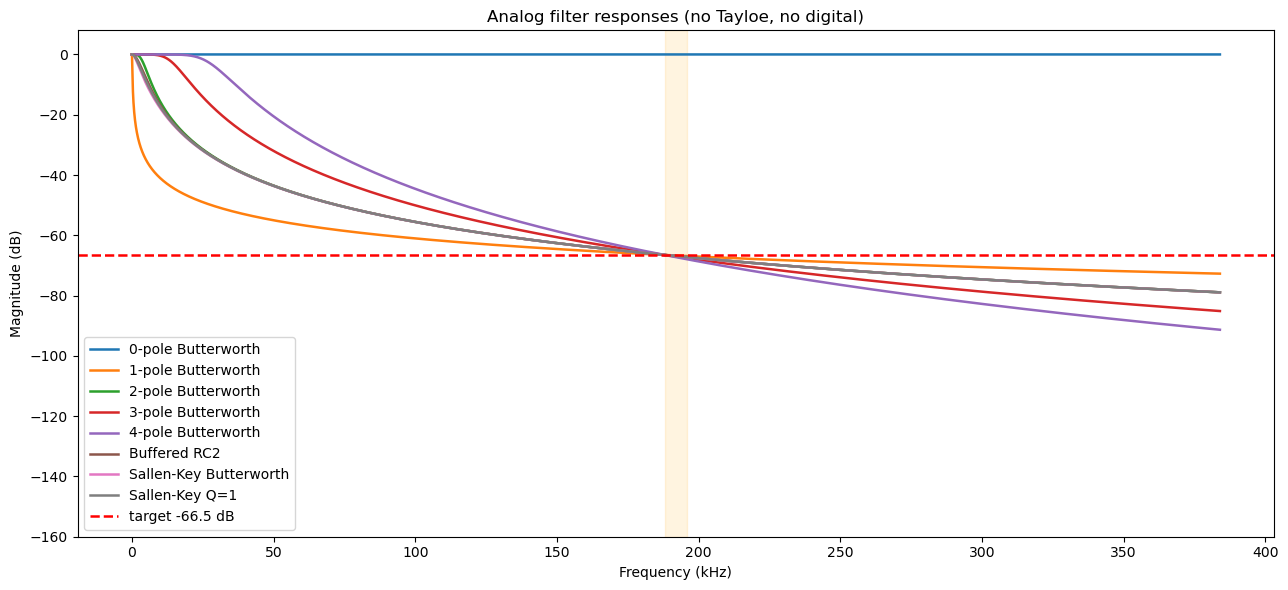

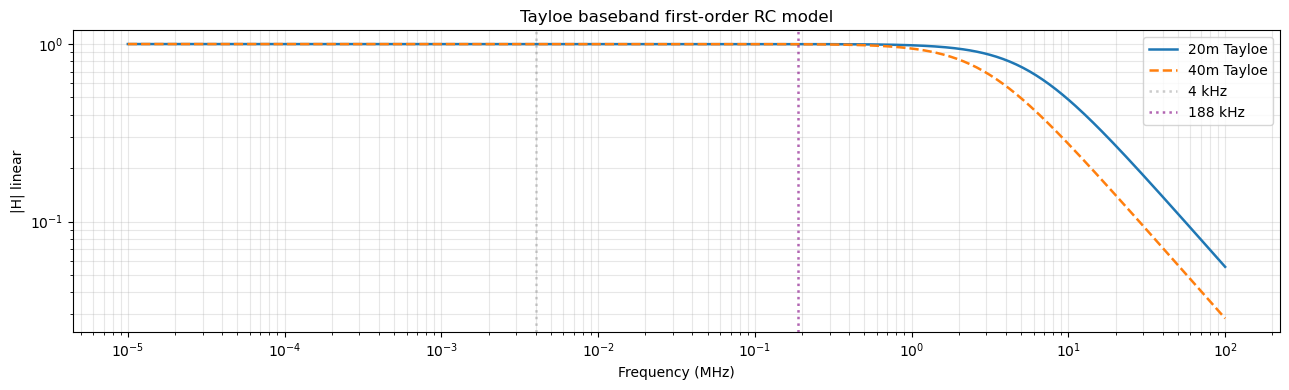

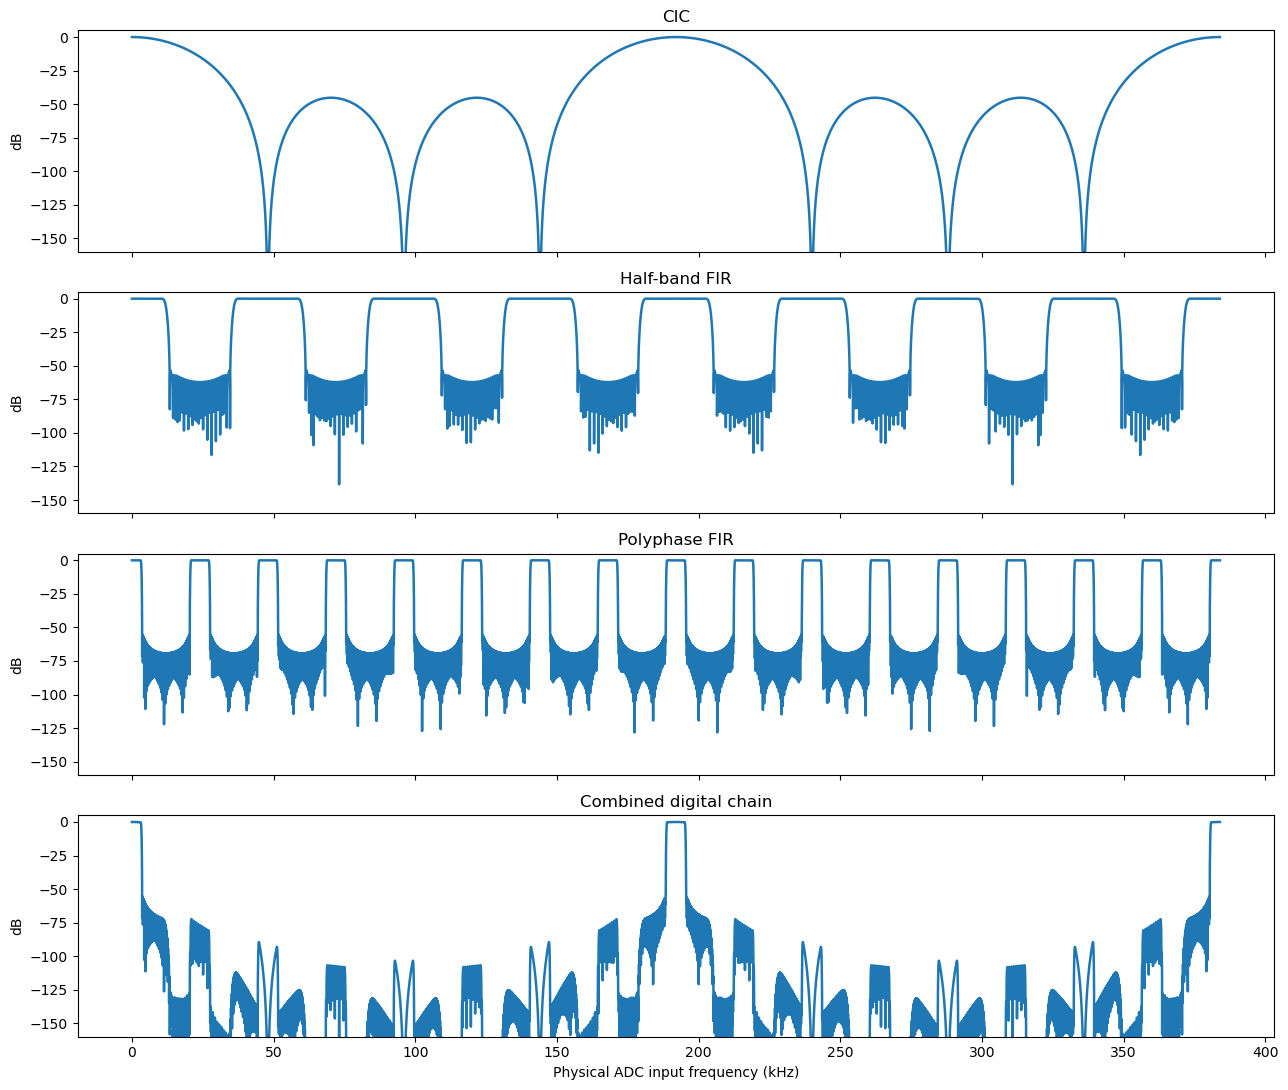

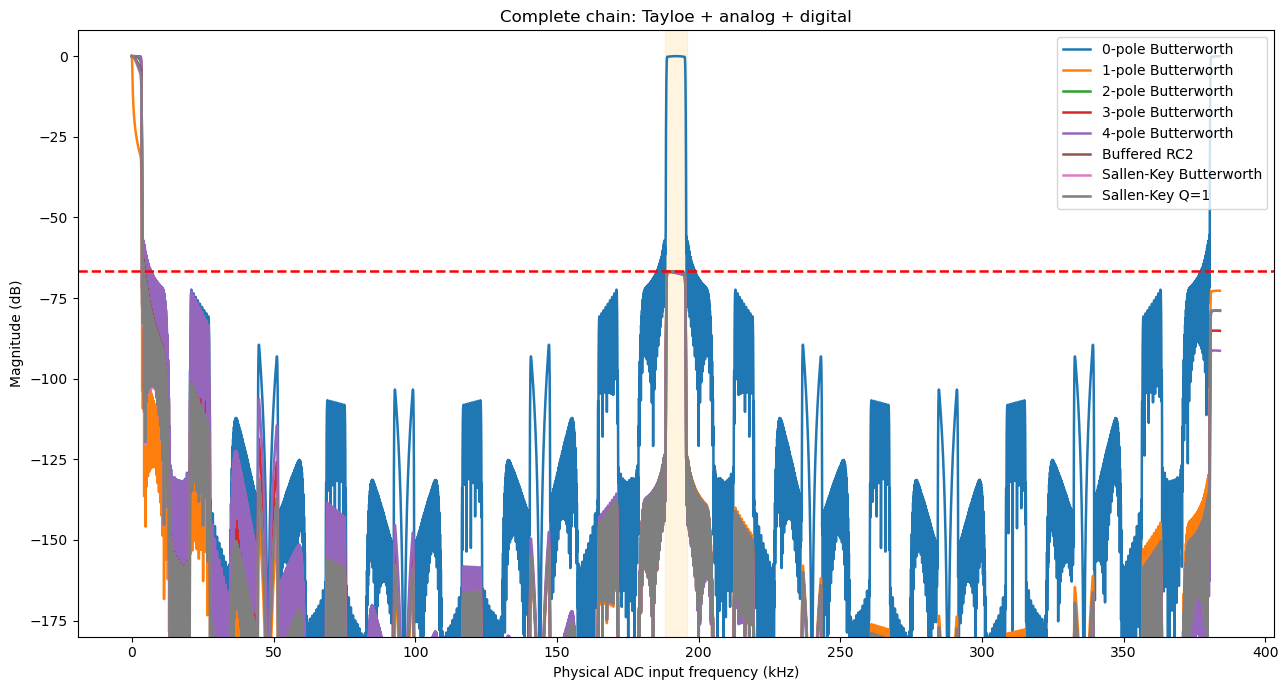

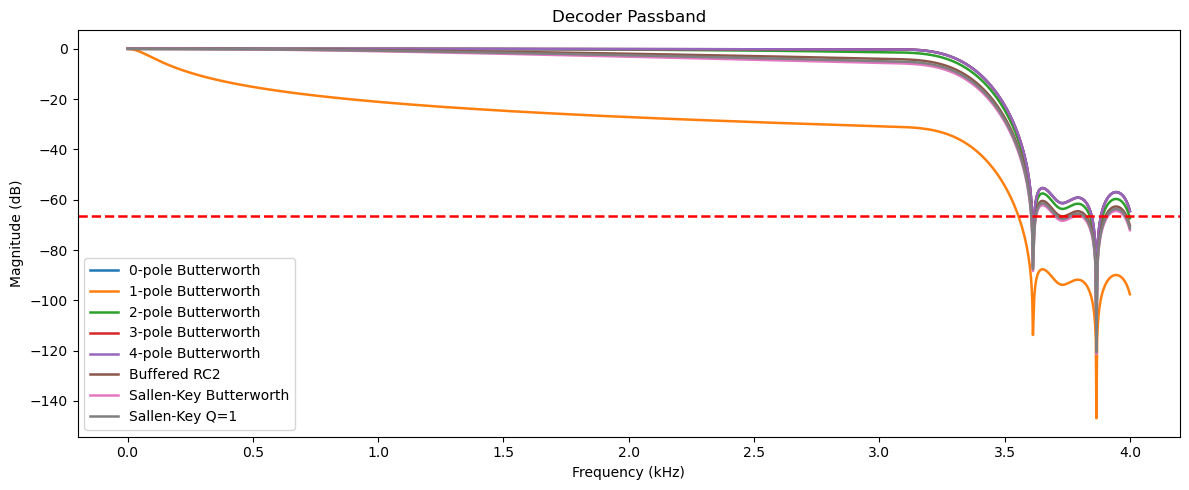

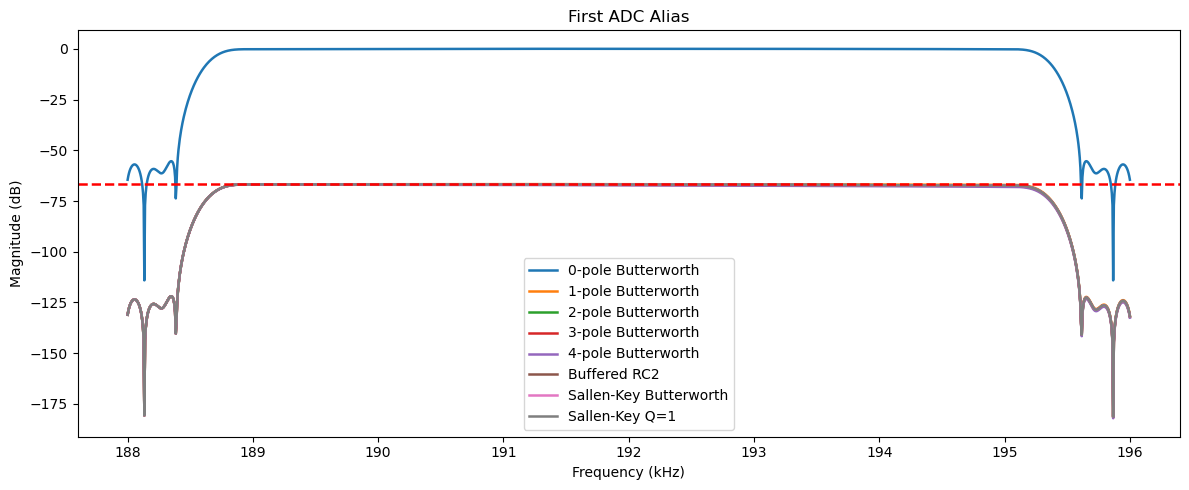

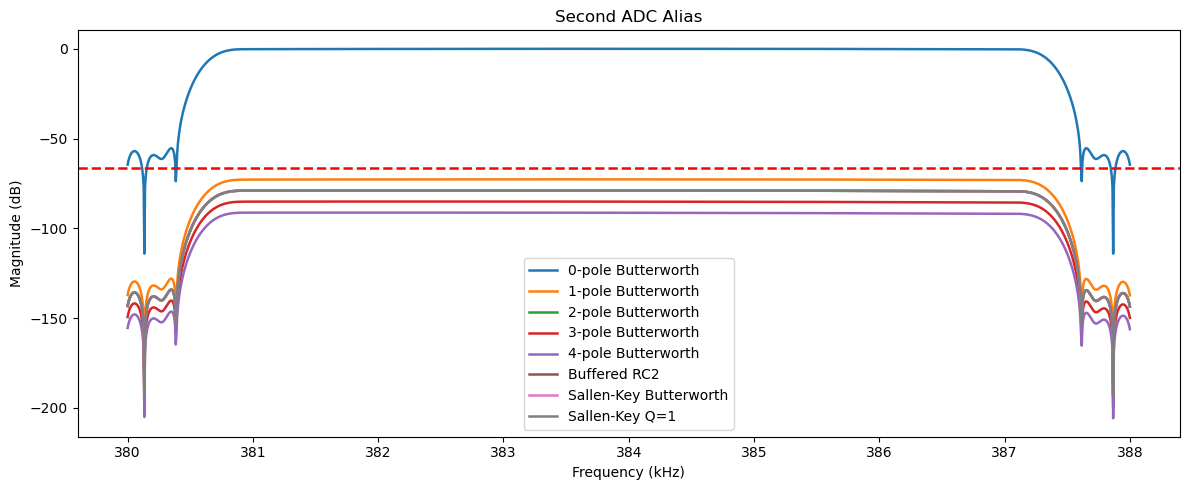

In [26]:
"""
audio_filter_chain.ipynb
========================

Complete audio filter chain: Tayloe baseband RC → analog AAF → ADC → digital.

Fixes:
  - Tayloe modeled as first-order RC (band-specific cap, Rs + Ron).
  - R_SOURCE split: RF impedance (Tayloe input, 8Ω) vs audio impedance
    (Tayloe output, 20Ω) used in passive RC ladder.
  - All print sections before any plot.

Alias rejection target derived from first principles:
    required = -BLOCKER_DBFS + (-DECODER_NOISE_DBFS) + ALIAS_BELOW_NOISE_DB
"""

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import firwin, freqz
from scipy.optimize import differential_evolution


# ============================================================
# CONFIGURATION
# ============================================================
FS = 192e3
FS1, FS2, FSOUT = 48e3, 24e3, 8e3
R_DEC, N_CIC = 4, 4

SSB = 2.7e3
FSOUT_NYQ = FSOUT / 2

FCRIT = FS - FSOUT_NYQ
FCRIT_HI = FS + FSOUT_NYQ
FCRIT2 = 2*FS - FSOUT_NYQ
FCRIT2_HI = 2*FS + FSOUT_NYQ

# RF source impedance (Tayloe input, designed 8 ohm at RF)
R_SOURCE_RF = 8.0
# 74CBTLV3253 on-resistance
R_ON_TAYLOE = 5.0

# Tayloe sampling caps (band-dependent)
C_TAYLOE_20M = 2.2e-9
C_TAYLOE_40M = 4.3e-9

# Tayloe baseband first-order RC corner (per band)
FC_TAYLOE_20M = 1/(2*np.pi*(R_SOURCE_RF + R_ON_TAYLOE) * C_TAYLOE_20M)
FC_TAYLOE_40M = 1/(2*np.pi*(R_SOURCE_RF + R_ON_TAYLOE) * C_TAYLOE_40M)
FC_TAYLOE = FC_TAYLOE_20M  # default band

# Audio-frequency source impedance seen by the filter (Tayloe output)
R_SOURCE_AUDIO = 20.0
R_ADC_LEAK = 1e12

# ADC
C_ADC = 6e-12
R_ADC_SWITCH = 0.0
T_ACQ = None
ADC_BITS = 12
ADC_VREF = 3.3
ADC_FS_PEAK = ADC_VREF / 2
ADC_LSB = ADC_VREF / (2**ADC_BITS)
ADC_SNR_TYP = 68.0
ADC_FS_DBM = +10.0

# Alias rejection target derivation
BLOCKER_DBFS = -30.0
ALIAS_BELOW_NOISE_DB = 10.0
DECODER_NOISE_DBFS = -ADC_SNR_TYP - 10*np.log10(FS/SSB)
ALIAS_THRESHOLD_DBFS = DECODER_NOISE_DBFS - ALIAS_BELOW_NOISE_DB
REQUIRED_REJECTION_DB = BLOCKER_DBFS - ALIAS_THRESHOLD_DBFS
TARGET = -REQUIRED_REJECTION_DB

MAX_PASS_LOSS_DB = 0.5

HB = firwin(63, 12e3, fs=FS1)
POLY = firwin(161, 3.35e3, fs=FS2)


# ============================================================
# UTILITIES
# ============================================================
def db(x):
    return 20*np.log10(np.maximum(np.abs(x), 1e-15))


def dbm_from_fs_dbfs(dbfs, full_scale_dbm=ADC_FS_DBM):
    return dbfs + full_scale_dbm


def wrap(f, fs):
    return (np.asarray(f) + fs/2) % fs - fs/2


def print_section(title):
    print()
    print("="*78)
    print(title)
    print("="*78)


# ============================================================
# TAYLOE MODEL
# ============================================================
def tayloe(f, fc_tayloe=FC_TAYLOE):
    """First-order RC, corner derived from band-specific hold cap."""
    return 1/(1 + 1j*np.asarray(f, float)/fc_tayloe)


# ============================================================
# ANALOG MODELS
# ============================================================
def butter(f, n, fc):
    f = np.asarray(f, float)
    if n == 0:
        return np.ones_like(f)
    return 1/np.sqrt(1+(f/fc)**(2*n))


def passive_rc(f, R1, R2, C1, C2):
    """Two-stage unbuffered RC ladder. Uses audio source impedance."""
    f = np.atleast_1d(np.asarray(f, float))
    s = 2j*np.pi*f
    H = np.zeros(len(f), dtype=complex)
    G1 = 1/(R_SOURCE_AUDIO + R1)
    G2 = 1/R2
    GL = 1/R_ADC_LEAK
    for i, si in enumerate(s):
        A = np.array([
            [G1+G2+si*C1, -G2],
            [-G2, G2+GL+si*C2]
        ], dtype=complex)
        b = np.array([G1, 0], dtype=complex)
        H[i] = np.linalg.solve(A, b)[1]
    return H


def buffered_rc(f, fc):
    return 1/(1+1j*np.asarray(f)/fc)**2


def sallen_key(f, fc, Q):
    s = 1j*np.asarray(f)/fc
    return 1/(1 - s**2 + s/Q)


def analog(f, c):
    typ = c["type"]
    if typ == "butter":
        return butter(f, c["n"], c["fc"])
    if typ == "passive":
        return passive_rc(f, c["R1"], c["R2"], c["C1"], c["C2"])
    if typ == "buffered":
        return buffered_rc(f, c["fc"])
    if typ == "sallen":
        return sallen_key(f, c["fc"], c["Q"])
    raise ValueError(typ)


# ============================================================
# ANALOG FILTER CONFIGURATIONS
# ============================================================
filters = {}

for n in range(5):
    fc = None if n == 0 else (
        FCRIT / (10**(-TARGET/10)-1)**(1/(2*n))
    )
    filters[f"{n}-pole Butterworth"] = {"type": "butter", "n": n, "fc": fc}

fc_buffered = FCRIT / np.sqrt(10**(-TARGET/20)-1)
filters["Buffered RC2"] = {"type": "buffered", "fc": fc_buffered}

fc_sk = FCRIT / (10**(-TARGET/10)-1)**0.25
filters["Sallen-Key Butterworth"] = {"type": "sallen", "fc": fc_sk, "Q": 1/np.sqrt(2)}
filters["Sallen-Key Q=1"] = {"type": "sallen", "fc": fc_sk, "Q": 1.0}


# ============================================================
# PASSIVE RC2 OPTIMIZATION
# ============================================================
f_pass = np.linspace(0, SSB, 250)
f_alias = np.linspace(FCRIT, FCRIT_HI, 500)

def passive_objective(x):
    R1, R2, C1, C2 = 10**np.asarray(x)
    hp = db(passive_rc(f_pass, R1, R2, C1, C2))
    ha = db(passive_rc(f_alias, R1, R2, C1, C2))
    pass_loss = -np.min(hp)
    violation = max(0, pass_loss - MAX_PASS_LOSS_DB)
    alias_miss = max(0, np.max(ha) - TARGET)
    return alias_miss**2 + 1000*violation**2

bounds = [(0, 5), (0, 5), (-12, -5), (-12, -5)]

result = differential_evolution(
    passive_objective, bounds,
    seed=42, popsize=20, maxiter=500, tol=1e-7, polish=True
)

R1_opt, R2_opt, C1_opt, C2_opt = 10**result.x
hp_opt = db(passive_rc(f_pass, R1_opt, R2_opt, C1_opt, C2_opt))
ha_opt = db(passive_rc(f_alias, R1_opt, R2_opt, C1_opt, C2_opt))

passive_feasible = (np.min(hp_opt) >= -MAX_PASS_LOSS_DB) and (np.max(ha_opt) <= TARGET)

# ============================================================
# ADC SETTLING
# ============================================================
def adc_settling(Rth, C=C_ADC, Rswitch=R_ADC_SWITCH):
    tau = (Rth+Rswitch)*C
    required = (ADC_BITS+1)*np.log(2)*tau
    return tau, required

RTH_PASSIVE = R_SOURCE_AUDIO + R1_opt + R2_opt
tau_passive, t_req_passive = adc_settling(RTH_PASSIVE)

RTH_ACTIVE = 100.0
tau_active, t_req_active = adc_settling(RTH_ACTIVE)

# STM32U375 at 192 kSps, dual ADC, T_acq = 0.5 * T_conv = 2600 ns
T_ACQ_DEFAULT = 2600e-9


# ============================================================
# DIGITAL CHAIN
# ============================================================
def cic(f):
    f = np.asarray(f, float)
    den = 4*np.sin(np.pi*f/FS)
    num = np.sin(4*np.pi*f/FS)
    ratio = np.ones_like(f)
    mask = np.abs(den) > 1e-12
    ratio[mask] = num[mask]/den[mask]
    return np.abs(ratio)**4


def fir_response(f, coeff, fs):
    _, h = freqz(coeff, worN=2*np.pi*np.asarray(f)/fs)
    return np.abs(h)


def digital(f):
    f = np.asarray(f, float)
    h1 = cic(wrap(f, FS))
    h2 = fir_response(wrap(f, FS1), HB, FS1)
    h3 = fir_response(wrap(f, FS2), POLY, FS2)
    return h1, h2, h3, h1*h2*h3


def complete(f, c):
    """Full chain: Tayloe × analog × digital."""
    return tayloe(f) * analog(f, c) * digital(f)[3]


# ============================================================
# PRINT: TAYLOE BASEBAND MODEL
# ============================================================
print_section("TAYLOE BASEBAND MODEL")
print(f"R_SOURCE_RF (RF input impedance):   {R_SOURCE_RF:.1f} ohm (by design)")
print(f"R_on (74CBTLV3253):                 {R_ON_TAYLOE:.1f} ohm")
print()
print(f"20m: C = {C_TAYLOE_20M*1e9:.1f} nF  ->  fc = {FC_TAYLOE_20M/1e6:.3f} MHz")
print(f"40m: C = {C_TAYLOE_40M*1e9:.1f} nF  ->  fc = {FC_TAYLOE_40M/1e6:.3f} MHz")
print(f"Default (20m): fc = {FC_TAYLOE/1e6:.3f} MHz")
print()
print("Response at key frequencies (20m Tayloe):")
print(f"  {'freq (kHz)':>12} {'|H_tayloe| (dB)':>18}")
print("-"*32)
for f in [1e3, 4e3, 8e3, 16e3, 24e3, 48e3, 96e3, FCRIT, FCRIT_HI]:
    print(f"  {f/1e3:>12.1f} {db(tayloe([f]))[0]:>18.4f}")


# ============================================================
# PRINT: PASSIVE RC2 OPTIMIZATION
# ============================================================
print_section("PASSIVE RC2 OPTIMIZATION")
print(f"Audio source impedance used:  {R_SOURCE_AUDIO:.1f} ohm (Tayloe output)")
print(f"R1:                  {R1_opt:.2f} ohm")
print(f"R2:                  {R2_opt:.2f} ohm")
print(f"C1:                  {C1_opt*1e9:.3f} nF")
print(f"C2:                  {C2_opt*1e9:.3f} nF")
print(f"Gain at 2.7 kHz:     {hp_opt[-1]:.3f} dB")
print(f"Worst passband:      {np.min(hp_opt):.3f} dB")
print(f"Worst alias:         {np.max(ha_opt):.3f} dB")
print(f"Target rejection:    {TARGET:.3f} dB")
print(f"Optimizer success:   {result.success}")
print(f"Optimizer nit:       {result.nit}")
print(f"Optimizer nfev:      {result.nfev}")
print(f"Final objective:     {result.fun:.4f}")
print(f"Design feasible:     {passive_feasible}")

if passive_feasible:
    filters["Passive unbuffered RC2"] = {
        "type": "passive",
        "R1": R1_opt, "R2": R2_opt,
        "C1": C1_opt, "C2": C2_opt,
        "fc": None
    }


# ============================================================
# PRINT: ADC SETTLING
# ============================================================
print_section("ADC SWITCHED-CAPACITOR MODEL")
print(f"Sampling capacitor:       {C_ADC*1e12:.2f} pF")
print(f"Switch resistance:        {R_ADC_SWITCH:.2f} ohm")
print(f"ADC bits:                 {ADC_BITS}")
print(f"ADC Vref:                 {ADC_VREF:.2f} V")
print(f"ADC LSB:                  {ADC_LSB*1e6:.1f} uV")
print(f"ADC full-scale peak:      {ADC_FS_PEAK:.2f} V")
print(f"ADC full-scale power:     {ADC_FS_DBM:+.1f} dBm")
print()
print(f"Passive ladder Rth (audio): {RTH_PASSIVE:.2f} ohm")
print(f"  tau:                      {tau_passive*1e9:.2f} ns")
print(f"  settling (12-bit):        {t_req_passive*1e9:.2f} ns")
print()
print(f"Active filter output Rth:   {RTH_ACTIVE:.0f} ohm (typical op-amp)")
print(f"  tau:                      {tau_active*1e9:.2f} ns")
print(f"  settling (12-bit):        {t_req_active*1e9:.2f} ns")
print()
print(f"STM32U375 at 192 kSps, dual ADC, T_acq = {T_ACQ_DEFAULT*1e9:.0f} ns:")
print(f"  passive ladder: {'PASS' if T_ACQ_DEFAULT >= t_req_passive else 'FAIL'}")
print(f"  active filter:  {'PASS' if T_ACQ_DEFAULT >= t_req_active else 'FAIL'}")


# ============================================================
# PRINT: ALIAS REJECTION TARGET DERIVATION
# ============================================================
print_section("ALIAS REJECTION TARGET DERIVATION")
print(f"ADC SNR typical:                    {ADC_SNR_TYP:+.1f} dB")
print(f"Decimation processing gain:         {10*np.log10(FS/SSB):+.1f} dB")
print(f"Decoder noise floor ({SSB/1e3:.1f} kHz BW):  {DECODER_NOISE_DBFS:+.1f} dBFS")
print(f"  = {dbm_from_fs_dbfs(DECODER_NOISE_DBFS):+.1f} dBm equivalent")
print()
print(f"Assumed max blocker at F_crit:      {BLOCKER_DBFS:+.1f} dBFS")
print(f"Alias must be {ALIAS_BELOW_NOISE_DB:.0f} dB below noise:  {ALIAS_THRESHOLD_DBFS:+.1f} dBFS")
print(f"Required rejection:                 {REQUIRED_REJECTION_DB:.1f} dB")
print(f"Target (TARGET):                    {TARGET:+.1f} dB")


# ============================================================
# PRINT: SYSTEM
# ============================================================
print_section("SYSTEM")
print(f"ADC:                     {FS/1e3:.1f} kHz")
print(f"Decimation:              192 -> 48 -> 24 -> 8 kHz")
print(f"SSB bandwidth:           {SSB/1e3:.2f} kHz")
print(f"Decoder Nyquist:         {FSOUT_NYQ/1e3:.1f} kHz")
print(f"RF source impedance:     {R_SOURCE_RF:.2f} ohm")
print(f"Audio source impedance:  {R_SOURCE_AUDIO:.2f} ohm")
print(f"ADC load model:          Switched capacitor ({C_ADC*1e12:.1f} pF)")
print(f"First alias band:        {FCRIT/1e3:.1f} .. {FCRIT_HI/1e3:.1f} kHz")
print(f"Second alias band:       {FCRIT2/1e3:.1f} .. {FCRIT2_HI/1e3:.1f} kHz")
print(f"Alias target:            {TARGET:+.1f} dB at {FCRIT/1e3:.1f} kHz")


# ============================================================
# PRINT: ANALOG FILTERS (analog only, no Tayloe)
# ============================================================
print_section("ANALOG FILTERS (analog response only)")
print(f"{'Filter':<32s} {'fc kHz':>10s} {'@2.7k':>8s} {'@4k':>8s} {'@Fcrit':>10s} {'@Fcrit+4k':>12s}")
print("-"*84)

for name, c in filters.items():
    fc = c.get("fc")
    fc_text = "N/A" if fc is None else f"{fc/1e3:.4f}"
    att_ssb = db(analog(np.array([SSB]), c))[0]
    att_nyq = db(analog(np.array([FSOUT_NYQ]), c))[0]
    att_crit = db(analog(np.array([FCRIT]), c))[0]
    att_crit_hi = db(analog(np.array([FCRIT_HI]), c))[0]
    print(f"{name:<32s} {fc_text:>10s} {att_ssb:>8.2f} {att_nyq:>8.2f} "
          f"{att_crit:>10.2f} {att_crit_hi:>12.2f}")


# ============================================================
# PRINT: -3 dB CUTOFF
# ============================================================
print_section("-3 dB CUTOFF FREQUENCY (analog only)")
print(f"{'Filter':<32s} {'-3dB (kHz)':>14s} {'Passband @2.7k':>18s}")
print("-"*68)

f_sweep_cutoff = np.logspace(1, 6, 5000)
for name, c in filters.items():
    if c["type"] == "butter" and c.get("n", 1) == 0:
        print(f"{name:<32s} {'(bypass)':>14s} {0.0:>17.2f} dB")
        continue
    resp = db(analog(f_sweep_cutoff, c))
    idx = np.argmin(np.abs(resp - (-3.0)))
    print(f"{name:<32s} {f_sweep_cutoff[idx]/1e3:>14.4f} "
          f"{db(analog(np.array([SSB]), c))[0]:>17.2f} dB")


# ============================================================
# PRINT: PASSBAND RIPPLE
# ============================================================
print_section("PASSBAND RIPPLE (analog only, 100 Hz to 4 kHz)")
f_passband = np.linspace(100, 4000, 200)
print(f"{'Filter':<32s} {'min dB':>8s} {'max dB':>8s} {'ripple':>10s} {'Pass?':>6s}")
print("-"*72)

for name, c in filters.items():
    r = db(analog(f_passband, c))
    worst = np.min(r)
    ok = worst >= -MAX_PASS_LOSS_DB
    print(f"{name:<32s} {np.min(r):>8.2f} {np.max(r):>8.2f} "
          f"{np.max(r)-np.min(r):>10.2f} {('OK' if ok else 'FAIL'):>6s}")


# ============================================================
# PRINT: COMPONENT VALUES
# ============================================================
print_section("COMPONENT VALUES AT fc (R = 10 kOhm)")
for name, c in filters.items():
    if c["type"] not in ("butter", "sallen", "buffered"):
        continue
    if c.get("fc") is None:
        continue
    fc = c["fc"]
    print(f"\n{name}  (fc = {fc/1e3:.4f} kHz)")
    if c["type"] == "butter":
        n = c["n"]
        if n == 1:
            C = 1/(2*np.pi*fc*10e3)
            print(f"  R=10k, C={C*1e12:.1f} pF")
        elif n == 2:
            Q = 1/np.sqrt(2)
            C2 = 1/(2*np.pi*fc*10e3*2*Q)
            C1 = 4*Q*Q*C2
            print(f"  R1=R2=10k, C1={C1*1e12:.1f} pF, C2={C2*1e12:.1f} pF")
        elif n == 3:
            C2_sk = 1/(2*np.pi*fc*10e3*2*1.0)
            C1_sk = 4*1.0*1.0*C2_sk
            C3_rc = 1/(2*np.pi*fc*10e3)
            print(f"  SK: R1=R2=10k, C1={C1_sk*1e12:.1f} pF, C2={C2_sk*1e12:.1f} pF")
            print(f"  RC: R3=10k, C3={C3_rc*1e12:.1f} pF")
        elif n == 4:
            for label, Q in [("Stage1", 0.54120), ("Stage2", 1.30656)]:
                C2 = 1/(2*np.pi*fc*10e3*2*Q)
                C1 = 4*Q*Q*C2
                print(f"  {label} (Q={Q:.4f}): R1=R2=10k, C1={C1*1e12:.1f} pF, C2={C2*1e12:.1f} pF")
    elif c["type"] == "sallen":
        Q = c["Q"]
        C2 = 1/(2*np.pi*fc*10e3*2*Q)
        C1 = 4*Q*Q*C2
        print(f"  R1=R2=10k, C1={C1*1e12:.1f} pF, C2={C2*1e12:.1f} pF")
    elif c["type"] == "buffered":
        C = 1/(2*np.pi*fc*10e3)
        print(f"  R=10k, C={C*1e12:.1f} pF")


# ============================================================
# PRINT: COMPLETE CHAIN (Tayloe + analog + digital)
# ============================================================
print_section("COMPLETE CHAIN PERFORMANCE (Tayloe + analog + digital)")
print(f"{'Filter':<32s} {'@2.7k':>8s} {'@4k':>8s} {'@8k':>8s} {'@16k':>8s} "
      f"{'@Alias1':>9s} {'@Alias2':>9s}")
print("-"*96)

for name, c in filters.items():
    p27 = db(complete(np.array([SSB]), c))[0]
    p4 = db(complete(np.array([FSOUT_NYQ]), c))[0]
    p8 = db(complete(np.array([8e3]), c))[0]
    p16 = db(complete(np.array([16e3]), c))[0]
    a1 = np.max(db(complete(np.linspace(FCRIT, FCRIT_HI, 1001), c)))
    a2 = np.max(db(complete(np.linspace(FCRIT2, FCRIT2_HI, 1001), c)))
    print(f"{name:<32s} {p27:>8.2f} {p4:>8.2f} {p8:>8.2f} {p16:>8.2f} "
          f"{a1:>9.2f} {a2:>9.2f}")


# ============================================================
# PRINT: WATERFALL BANDWIDTH
# ============================================================
print_section("WATERFALL BANDWIDTH (complete chain, -6 dB)")
print(f"{'Filter':<32s} {'-6dB BW (kHz)':>14s}")
print("-"*50)

for name, c in filters.items():
    f_test = np.linspace(100, 48e3, 2000)
    resp = db(complete(f_test, c))
    under = f_test[resp < -6.0]
    bw = under[0] if len(under) else 48e3
    print(f"{name:<32s} {bw/1e3:>14.2f}")


# ============================================================
# PRINT: DECODER SIGNAL vs NOISE
# ============================================================
print_section("DECODER SIGNAL vs NOISE")
print(f"ADC SNR:                      {ADC_SNR_TYP:+.1f} dB")
print(f"Decimation gain (192k/2.7k):  {10*np.log10(FS/SSB):+.1f} dB")
print(f"Decoder noise in SSB BW:      {DECODER_NOISE_DBFS:+.1f} dBFS "
      f"({dbm_from_fs_dbfs(DECODER_NOISE_DBFS):+.1f} dBm)")
print()
print(f"Signal at full scale (0 dBFS):       {dbm_from_fs_dbfs(0):+.1f} dBm")
print(f"Signal at {BLOCKER_DBFS:+.0f} dBFS (assumed blocker):  "
      f"{dbm_from_fs_dbfs(BLOCKER_DBFS):+.1f} dBm")
print(f"Alias must be below:                 {ALIAS_THRESHOLD_DBFS:+.1f} dBFS")
print(f"Required rejection:                  {REQUIRED_REJECTION_DB:.1f} dB")
print(f"Current TARGET:                      {abs(TARGET):.1f} dB")
print(f"Status: {'PASS' if abs(TARGET) >= REQUIRED_REJECTION_DB else 'INSUFFICIENT'}")


# ============================================================
# PRINT: FINAL COMPARISON
# ============================================================
print_section("FINAL COMPARISON")
print(f"{'Filter':<32s} {'fc(kHz)':>9s} {'2.7k':>7s} {'Pass':>5s} "
      f"{'4k':>7s} {'8k':>7s} {'Alias1':>8s} {'Settle':>7s}")
print("-"*88)

for name, c in filters.items():
    fc = c.get("fc")
    fc_text = "Bypass" if fc is None else f"{fc/1e3:.2f}"

    p27 = db(complete(np.array([SSB]), c))[0]
    p4 = db(complete(np.array([FSOUT_NYQ]), c))[0]
    p8 = db(complete(np.array([8e3]), c))[0]
    a1 = np.max(db(complete(np.linspace(FCRIT, FCRIT_HI, 1001), c)))

    if c["type"] == "passive":
        Rth = R_SOURCE_AUDIO + c["R1"] + c["R2"]
    else:
        Rth = RTH_ACTIVE
    _, t_req = adc_settling(Rth)
    settle_ok = (T_ACQ_DEFAULT >= t_req)

    pass_ok = p27 >= -MAX_PASS_LOSS_DB

    print(f"{name:<32s} {fc_text:>9s} {p27:>7.2f} "
          f"{('OK' if pass_ok else 'FAIL'):>5s} "
          f"{p4:>7.2f} {p8:>7.2f} {a1:>8.2f} "
          f"{('PASS' if settle_ok else 'FAIL'):>7s}")

print("="*88)
print("END")


# ============================================================
# PLOTS
# ============================================================
f = np.linspace(0, 384e3, 12000)

# Plot 1: Analog filters (analog only)
fig, ax = plt.subplots(figsize=(13, 6))
for name, c in filters.items():
    ax.plot(f/1e3, db(analog(f, c)), label=name)
ax.axvspan(FCRIT/1e3, FCRIT_HI/1e3, color="orange", alpha=.12)
ax.axhline(TARGET, color="red", ls="--", label=f"target {TARGET:.1f} dB")
ax.set(xlabel="Frequency (kHz)", ylabel="Magnitude (dB)",
       title="Analog filter responses (no Tayloe, no digital)", ylim=(-160, 8))
ax.grid(); ax.legend()
plt.tight_layout(); plt.show()

# Plot 2: Tayloe response
fig, ax = plt.subplots(figsize=(13, 4))
f_tay = np.logspace(1, 8, 500)
ax.loglog(f_tay/1e6, np.abs(tayloe(f_tay, FC_TAYLOE_20M)), label="20m Tayloe")
ax.loglog(f_tay/1e6, np.abs(tayloe(f_tay, FC_TAYLOE_40M)), '--', label="40m Tayloe")
ax.axvline(4e-3, color="gray", ls=":", alpha=0.4, label="4 kHz")
ax.axvline(FCRIT/1e6, color="purple", ls=":", alpha=0.6, label="188 kHz")
ax.set(xlabel="Frequency (MHz)", ylabel="|H| linear",
       title="Tayloe baseband first-order RC model")
ax.grid(True, which="both", alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

# Plot 3: Digital chain
h1, h2, h3, ht = digital(f)
fig, axes = plt.subplots(4, 1, figsize=(13, 11), sharex=True)
for ax_i, h, nm in zip(axes, [h1, h2, h3, ht],
                        ["CIC", "Half-band FIR", "Polyphase FIR",
                         "Combined digital chain"]):
    ax_i.plot(f/1e3, db(h))
    ax_i.set_title(nm); ax_i.set_ylabel("dB"); ax_i.set_ylim(-160, 5); ax_i.grid()
axes[-1].set_xlabel("Physical ADC input frequency (kHz)")
plt.tight_layout(); plt.show()

# Plot 4: Complete chain
fig, ax = plt.subplots(figsize=(13, 7))
for name, c in filters.items():
    ax.plot(f/1e3, db(complete(f, c)), label=name)
ax.axvspan(FCRIT/1e3, FCRIT_HI/1e3, color="orange", alpha=.12)
ax.axhline(TARGET, color="red", ls="--")
ax.set(xlabel="Physical ADC input frequency (kHz)",
       ylabel="Magnitude (dB)",
       title="Complete chain: Tayloe + analog + digital", ylim=(-180, 8))
ax.grid(); ax.legend()
plt.tight_layout(); plt.show()

# Plots 5-7: Zoom-ins
for lo, hi, title in [
    (0, 4e3, "Decoder Passband"),
    (FCRIT, FCRIT_HI, "First ADC Alias"),
    (FCRIT2, FCRIT2_HI, "Second ADC Alias"),
]:
    ff = np.linspace(lo, hi, 1500)
    fig, ax = plt.subplots(figsize=(12, 5))
    for name, c in filters.items():
        ax.plot(ff/1e3, db(complete(ff, c)), label=name)
    ax.axhline(TARGET, color="red", ls="--")
    ax.set(xlabel="Frequency (kHz)", ylabel="Magnitude (dB)", title=title)
    ax.grid(); ax.legend()
    plt.tight_layout(); plt.show()